Historical notebook with corrected imports and kernel-grid construction. Outputs from unchanged cells are retained as historical results; outputs of updated cells have been cleared. Full notebook execution has not been rerun for this release. The SOCP sections require the optional CVXPY dependency. See the [current README](../../README.md) and [kernel guide](../../docs/kernel_dwd.md) for installation and supported usage.
The shared setup and kernel examples do not require CVXPY. If CVXPY is unavailable, the optional linear SOCP cells print a skip message; other import and solver errors still propagate. The final README kernel example includes its own imports and can run independently.


In [ ]:
from sklearn.datasets import make_blobs, make_circles
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
%matplotlib inline
import numpy as np

from dwd.gen_kern_dwd import KernGDWD
from dwd.viz import ABLine2D, clf2D_slope_intercept, get_mesh_grid

cm = plt.cm.RdBu
cm_bright = ListedColormap(['#FF0000', '#0000FF'])


In [ ]:
# Optional linear SOCP example (requires CVXPY).
try:
    from dwd.socp_dwd import DWD
except ModuleNotFoundError as exc:
    if exc.name != 'cvxpy':
        raise
    print('SOCP example skipped: CVXPY is not installed; see README for installation instructions.')
else:
    # sample sythetic training data
    X, y = make_blobs(n_samples=200, n_features=2,
                      centers=[[0, 0],
                               [2, 2]])

    # fit DWD classifier
    dwd = DWD(C='auto').fit(X, y)

    # compute training accuracy
    tr_acc = dwd.score(X, y)

    # plot points and DWD separting hyperplane
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cm_bright)
    ABLine2D(*clf2D_slope_intercept(clf=dwd),
             color='black',
             label='DWD separating hyperplane')
    plt.title('DWD linear classifier (tr acc = {})'.format(tr_acc))
    plt.legend()

Text(0.5, 1.0, 'DWD with Gaussian Kernel (tr acc = 0.915)')

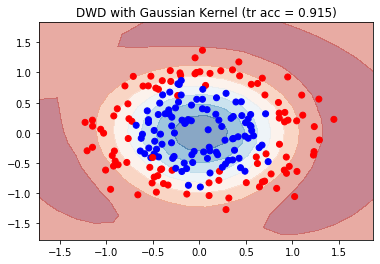

In [79]:
# sample some non-linear, toy data
X, y = make_circles(n_samples=200, noise=0.2, factor=0.5, random_state=1)

# fit kernel DWD wit gaussian kernel
kdwd = KernGDWD(lambd=.1, kernel='rbf',
                kernel_kws={'gamma': 1}).fit(X, y)

# compute training accuracy
tr_acc = kdwd.score(X, y)

# visualze the decision function and training points
X_mesh, xx, yy = get_mesh_grid(X)
f = kdwd.decision_function(X_mesh)
f = f.reshape(xx.shape)
plt.contourf(xx, yy, f, cmap=cm, alpha=.5)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cm_bright)
plt.title('DWD with Gaussian Kernel (tr acc = {})'.format(tr_acc))

## Linear DWD on two synthetic clusters

In [ ]:
from sklearn.datasets import make_blobs

# Optional linear SOCP example (requires CVXPY).
try:
    from dwd.socp_dwd import DWD
except ModuleNotFoundError as exc:
    if exc.name != 'cvxpy':
        raise
    print('SOCP example skipped: CVXPY is not installed; see README for installation instructions.')
else:
    # sample sythetic training data
    X, y = make_blobs(n_samples=200, n_features=2,
                      centers=[[0, 0],
                               [2, 2]])

    # fit DWD classifier
    dwd = DWD(C='auto').fit(X, y)

    # compute training accuracy
    print(dwd.score(X, y))

In [ ]:
from sklearn.datasets import make_circles
from dwd.gen_kern_dwd import KernGDWD

# sample some non-linear, toy data
X, y = make_circles(n_samples=200, noise=0.2, factor=0.5, random_state=1)

# fit kernel DWD wit gaussian kernel
kdwd = KernGDWD(lambd=.1, kernel='rbf',
                kernel_kws={'gamma': 1}).fit(X, y)

# compute training accuracy
kdwd.score(X, y)